<a href="https://colab.research.google.com/github/dritireddy/Consumer-Product-Preference-Analysis/blob/main/Consumer_Product_Preference_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import libraries and load the dataset**

In [41]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")


Libraries imported successfully!


**Upload and load CSV in Colab**

In [42]:

from google.colab import files

uploaded = files.upload()


Saving Product_Preference_Analysis.csv to Product_Preference_Analysis (2).csv


In [43]:

df = pd.read_csv("Product_Preference_Analysis.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


**Inspect the dataset**

In [44]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000



Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Duplicate rows: 0


**Q1 —What are the average, minimum, and maximum transaction sales for each product line?[CO1, BL3]**

In [45]:
product_lines = df["Product line"].unique()

for product in product_lines:
    sales = df.loc[
        df["Product line"] == product, "Sales"
    ].to_numpy()

    print("\nProduct line:", product)
    print("Average sales:", np.mean(sales).round(2))
    print("Minimum sales:", np.min(sales).round(2))
    print("Maximum sales:", np.max(sales).round(2))


Product line: Health and beauty
Average sales: 323.64
Minimum sales: 18.64
Maximum sales: 950.25

Product line: Electronic accessories
Average sales: 319.63
Minimum sales: 26.72
Maximum sales: 942.45

Product line: Home and lifestyle
Average sales: 336.64
Minimum sales: 14.68
Maximum sales: 1023.75

Product line: Sports and travel
Average sales: 332.07
Minimum sales: 10.68
Maximum sales: 1002.12

Product line: Food and beverages
Average sales: 322.67
Minimum sales: 22.66
Maximum sales: 1034.46

Product line: Fashion accessories
Average sales: 305.09
Minimum sales: 12.69
Maximum sales: 1042.65


In [46]:
# Array creation, indexing and slicing
sales_arr = df["Sales"].to_numpy()
print(sales_arr.shape, sales_arr[:5], sales_arr[-5:])
print("Sales above 500:", sales_arr[sales_arr > 500][:5])   # boolean indexing

# Arithmetic
unit_arr = df["Unit price"].to_numpy()
qty_arr = df["Quantity"].to_numpy()
pre_tax = unit_arr * qty_arr          # element-wise multiplication
print(pre_tax[:5])

# 2-D array and transpose
matrix = df[["Unit price", "Quantity", "Sales", "Rating"]].to_numpy()
print(matrix.shape, "->", matrix.T.shape)
print("Column means:", matrix.mean(axis=0).round(2))

# Random numbers: sample 100 transactions and compare with the full data
rng = np.random.default_rng(42)
sample = rng.choice(sales_arr, size=100, replace=False)
print("Sample mean:", sample.mean().round(2), "| Population mean:", sales_arr.mean().round(2))

(1000,) [548.9715  80.22   340.5255 489.048  634.3785] [  42.3675 1022.49     33.432    69.111   649.299 ]
Sales above 500: [548.9715 634.3785 627.6165 772.38   749.49  ]
[522.83  76.4  324.31 465.76 604.17]
(1000, 4) -> (4, 1000)
Column means: [ 55.67   5.51 322.97   6.97]
Sample mean: 303.21 | Population mean: 322.97


**Q2 — Which product lines perform best in total sales and quantity, and how do patterns differ by gender and customer type? [CO2, BL4]**

A — Product line performance:

In [47]:
product_analysis = df.groupby("Product line").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Sales=("Sales", "mean"),
    Average_Rating=("Rating", "mean")
).round(2)

product_analysis = product_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(product_analysis)

print("Highest-sales product line:",
      product_analysis["Total_Sales"].idxmax())

print("Most-purchased product line:",
      product_analysis["Total_Quantity"].idxmax())

,Total_Sales,Total_Quantity,Average_Sales,Average_Rating
Product line,,,,
Food and beverages,56144.84,952,322.67,7.11
Sports and travel,55122.83,920,332.07,6.92
Electronic accessories,54337.53,971,319.63,6.92
Fashion accessories,54305.90,902,305.09,7.03
Home and lifestyle,53861.91,911,336.64,6.84
Health and beauty,49193.74,854,323.64,7.00


Highest-sales product line: Food and beverages
Most-purchased product line: Electronic accessories


B — Preferences by gender:

In [48]:
gender_analysis = df.groupby(
    ["Gender", "Product line"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(gender_analysis)

Total_Sales  Total_Quantity
Gender Product line                                       
Female Electronic accessories     31226.71             548
       Fashion accessories        33919.64             586
       Food and beverages         36465.80             568
       Health and beauty          23418.73             425
       Home and lifestyle         33720.58             561
       Sports and travel          35920.38             600
Male   Electronic accessories     23110.83             423
       Fashion accessories        20386.25             316
       Food and beverages         19679.05             384
       Health and beauty          25775.01             429
       Home and lifestyle         20141.33             350
       Sports and travel          19202.44             320

C — Preferences by customer type:

In [49]:
customer_analysis = df.groupby("Customer type").agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(customer_analysis)

,Total_Sales,Average_Sales,Total_Quantity
Customer type,,,
Member,189694.76,335.74,3181
Normal,133271.98,306.37,2329


Q3 — Are there missing values or duplicate records, and how are they handled [CO3, BL3]

In [50]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")

# Fill missing numerical values with the median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with "Unknown"
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

# Fill any missing dates using the most frequent date
if df["Date"].isnull().any() and df["Date"].notna().any():
    df["Date"] = df["Date"].fillna(df["Date"].mode()[0])

print("Dataset shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (1000, 17)
Total missing values: 0
Duplicate rows: 0


Categorizing values, hierarchical indexing and reshaping

In [72]:
# Categorize transaction sales
df["Sales Category"] = pd.cut(
    df["Sales"],
    bins=[0, 200, 500, float("inf")],
    labels=["Low", "Medium", "High"]
)

display(df[["Sales", "Sales Category"]].head())

# Hierarchical indexing
multi_index = df.set_index(["City", "Product line"])
display(multi_index[["Sales"]].head())

# Reshape data using melt
reshaped = pd.melt(
    df.head(5),
    id_vars=["City"],
    value_vars=["Sales", "Quantity"],
    var_name="Measure",
    value_name="Value"
)
display(reshaped)

,Sales,Sales Category
0,548.9715,High
1,80.2200,Low
2,340.5255,Medium
3,489.0480,Medium
4,634.3785,High


Sales
City      Product line                    
Yangon    Health and beauty       548.9715
Naypyitaw Electronic accessories   80.2200
Yangon    Home and lifestyle      340.5255
          Health and beauty       489.0480
          Sports and travel       634.3785

,City,Measure,Value
0,Yangon,Sales,548.9715
1,Naypyitaw,Sales,80.2200
2,Yangon,Sales,340.5255
3,Yangon,Sales,489.0480
4,Yangon,Sales,634.3785
5,Yangon,Quantity,7.0000
6,Naypyitaw,Quantity,5.0000
7,Yangon,Quantity,7.0000
8,Yangon,Quantity,8.0000
9,Yangon,Quantity,7.0000


Merging sales per city

In [71]:
city_stats = df.groupby("City", as_index=False).agg(
    Avg_Rating=("Rating", "mean"),
    Transactions=("Invoice ID", "count")
).round(2)

merged_data = pd.merge(city_sales, city_stats, on="City")
display(merged_data)

,City,Sales,Avg_Rating,Transactions
0,Mandalay,106197.6720,6.82,332
1,Naypyitaw,110568.7065,7.07,328
2,Yangon,106200.3705,7.03,340


**Correlation Analysis**

correlation matrix

In [53]:
numeric_cols = [
    "Unit price",
    "Quantity",
    "Sales",
    "gross income",
    "Rating"
]

correlation_matrix = df[numeric_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Unit price,Quantity,Sales,gross income,Rating
Unit price,1.00,0.01,0.63,0.63,-0.01
Quantity,0.01,1.00,0.71,0.71,-0.02
Sales,0.63,0.71,1.00,1.00,-0.04
gross income,0.63,0.71,1.00,1.00,-0.04
Rating,-0.01,-0.02,-0.04,-0.04,1.00


Heatmap

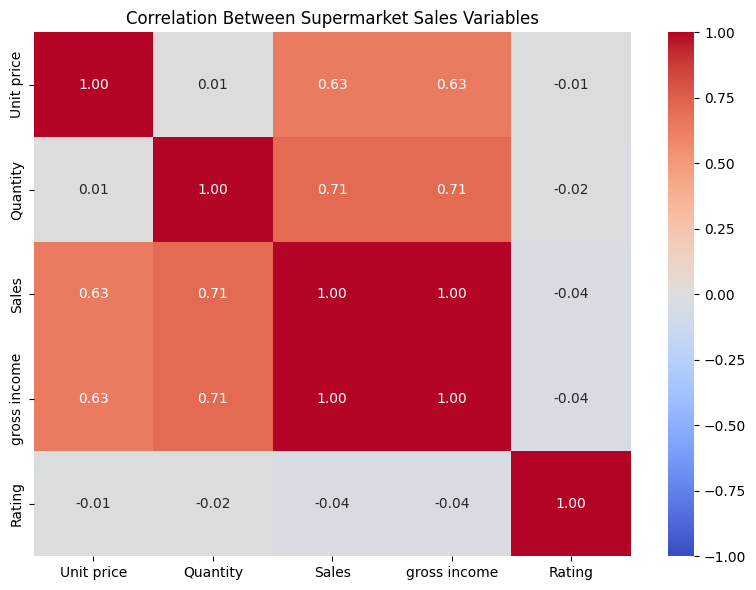

In [54]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Supermarket Sales Variables")
plt.tight_layout()
plt.show()

**Q4 — How do sales vary across cities and dates, and what relationships exist among numerical variables? [CO4, BL4]**

A — Sales by city and customer type:

In [55]:
city_analysis = df.groupby(
    ["City", "Customer type"]
).agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(city_analysis)

print("City with highest sales:",
      df.groupby("City")["Sales"].sum().idxmax())

Total_Sales  Average_Sales  Total_Quantity
City      Customer type                                            
Mandalay  Member            59824.17         330.52            1002
          Normal            46373.50         307.11             818
Naypyitaw Member            66974.82         345.23            1073
          Normal            43593.89         325.33             758
Yangon    Member            62895.78         331.03            1106
          Normal            43304.59         288.70             753

City with highest sales: Naypyitaw


B — Daily sales trend:

,Sales
Date,
2019-01-01,4745.1810
2019-01-02,1945.5030
2019-01-03,2078.1285
2019-01-04,1623.6885
2019-01-05,3536.6835


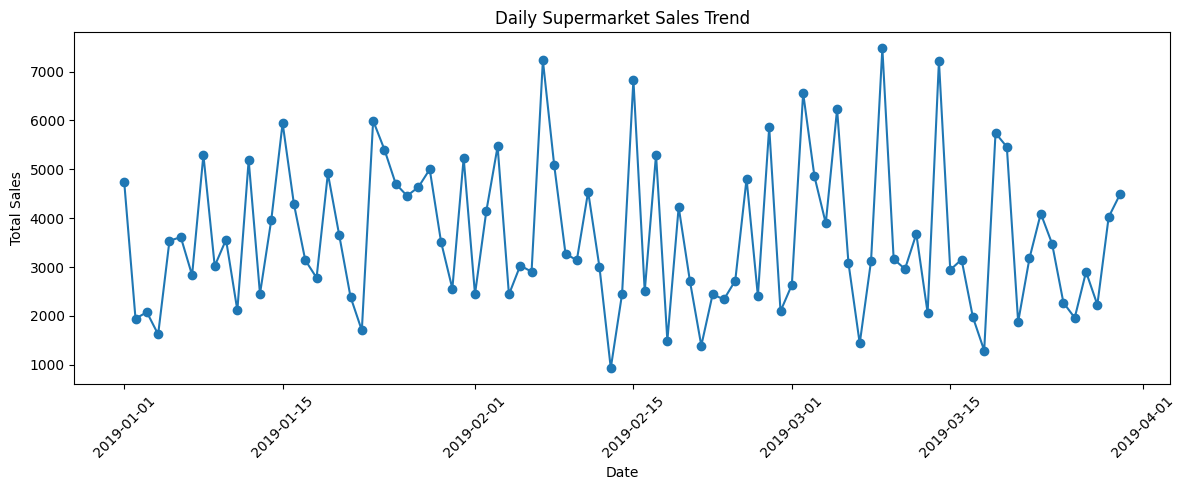

In [56]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

daily_sales = (
    df.dropna(subset=["Date"])
      .groupby(df["Date"].dt.date)["Sales"]
      .sum()
      .sort_index()
)

display(daily_sales.head())

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")
plt.title("Daily Supermarket Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly sales resampling and time-based filtering

Sales in January 2019:


,Sales
Date,
2019-01-01,177.408
2019-01-01,621.243
2019-01-01,399.756
2019-01-01,113.568
2019-01-01,132.027


,Sales
Date,
2019-01-01,116291.868
2019-02-01,97219.374
2019-03-01,109455.507


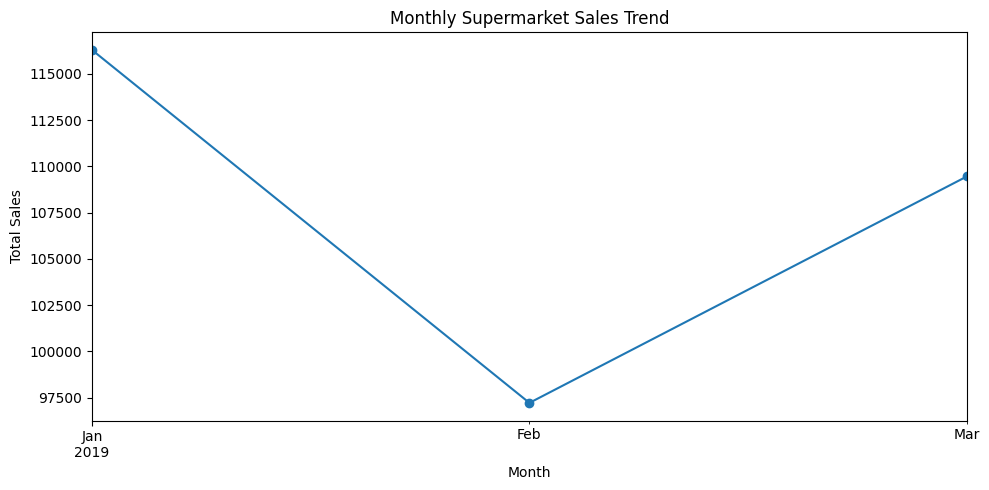

In [57]:
# Set Date as the index
time_data = df.dropna(subset=["Date"]).set_index("Date").sort_index()

# Select a date range
print("Sales in January 2019:")
display(time_data.loc["2019-01", ["Sales"]].head())

# Resample daily sales into monthly totals
monthly_sales = time_data["Sales"].resample("MS").sum()

display(monthly_sales)

# Plot monthly sales
plt.figure(figsize=(10, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Supermarket Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [58]:
peak_date = daily_sales.idxmax()

peak_transactions = df[
    df["Date"].dt.date == peak_date
]

print("Peak date:", peak_date)
print("Total sales:", round(daily_sales.max(), 2))
print("Number of transactions:", len(peak_transactions))
print("Total quantity sold:", peak_transactions["Quantity"].sum())

print("\nSales by product line:")
display(
    peak_transactions.groupby("Product line")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

Peak date: 2019-03-09
Total sales: 7474.05
Number of transactions: 16
Total quantity sold: 99

Sales by product line:


,Sales
Product line,
Fashion accessories,2010.8970
Sports and travel,1877.9565
Food and beverages,1459.1115
Electronic accessories,980.0070
Health and beauty,762.5520
Home and lifestyle,383.5230


**Q5 — What do bar plots, a scatter plot, a pie chart, a line plot, and heatmaps reveal about sales and product preferences? [CO5, BL5]**

---



Total sales by product line:

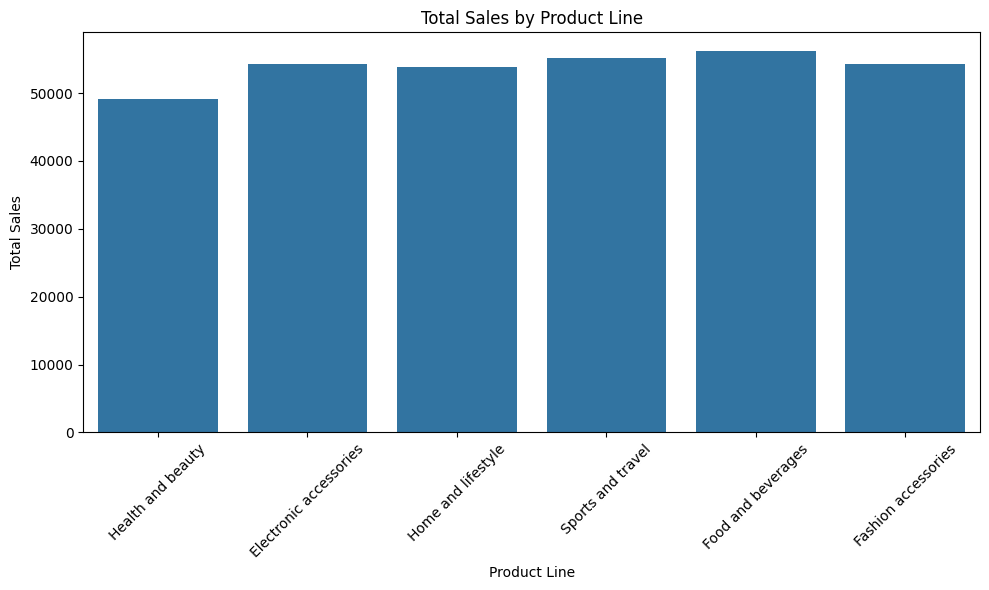

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Product line",
    y="Sales",
    estimator=sum,
    errorbar=None
)

plt.title("Total Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Quantity sold by product line:


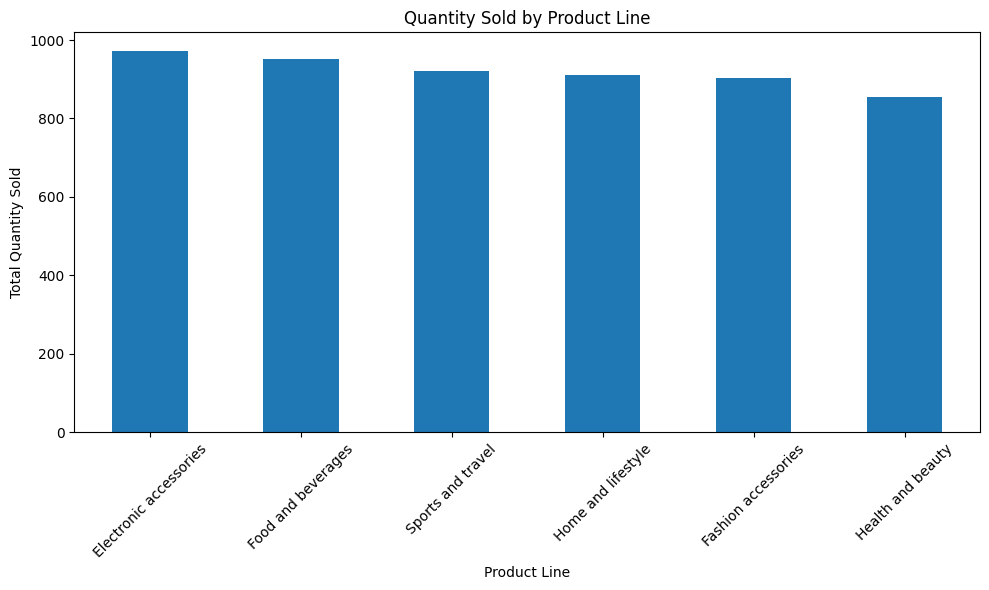

In [60]:
quantity_data = df.groupby(
    "Product line"
)["Quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
quantity_data.plot(kind="bar")

plt.title("Quantity Sold by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Heatmap of sales by city and product line:




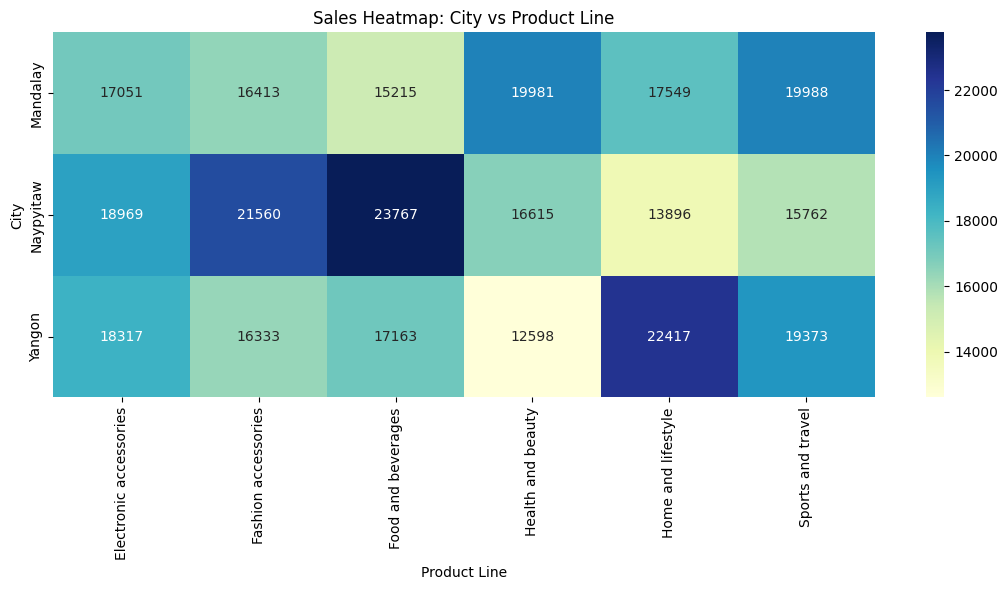

In [61]:
sales_pivot = df.pivot_table(
    index="City",
    columns="Product line",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(11, 6))
sns.heatmap(sales_pivot, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Sales Heatmap: City vs Product Line")
plt.xlabel("Product Line")
plt.ylabel("City")
plt.tight_layout()
plt.show()

Payment method distribution:

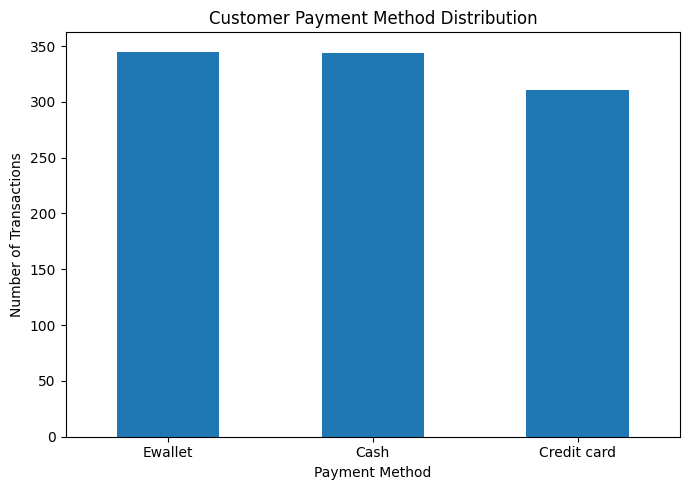

In [62]:
payment_counts = df["Payment"].value_counts()

plt.figure(figsize=(7, 5))
payment_counts.plot(kind="bar")

plt.title("Customer Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

 Sales by product Line

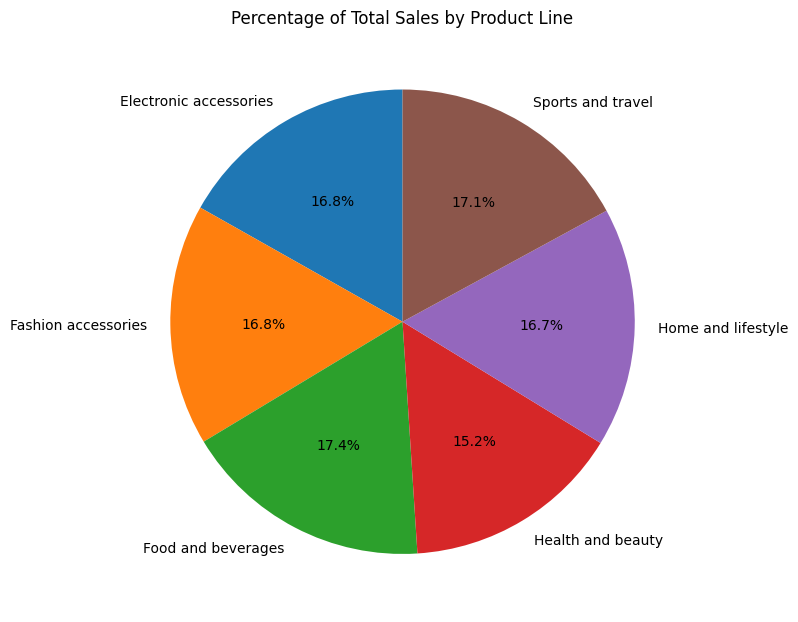

In [63]:
product_sales = df.groupby("Product line")["Sales"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    product_sales,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Total Sales by Product Line")
plt.tight_layout()
plt.show()

Sales by City — Bar Plot

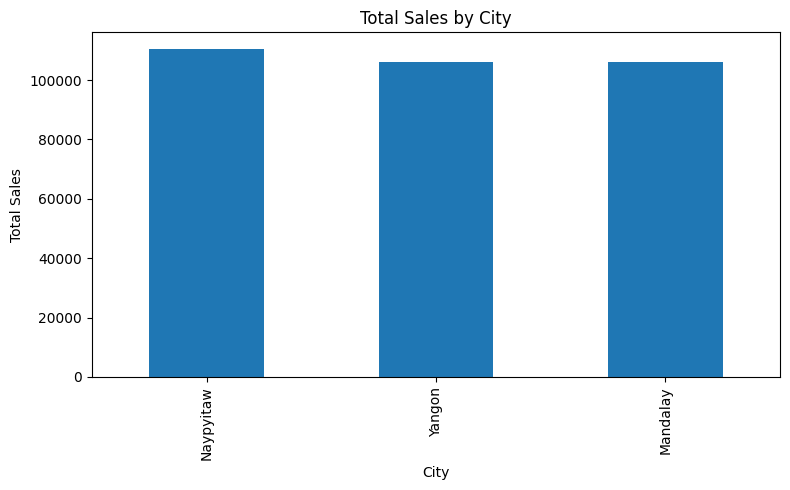

In [64]:
city_totals = df.groupby("City")["Sales"].sum().sort_values(ascending=False)

city_totals.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

Quantity Distribution — Histogram

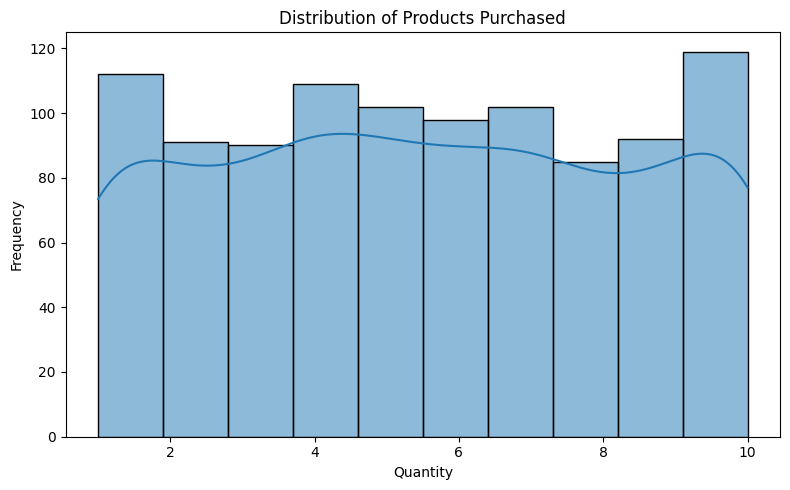

In [65]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Quantity", bins=10, kde=True)

plt.title("Distribution of Products Purchased")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Scatter Plot-Unit Price vs Sales by Product Line



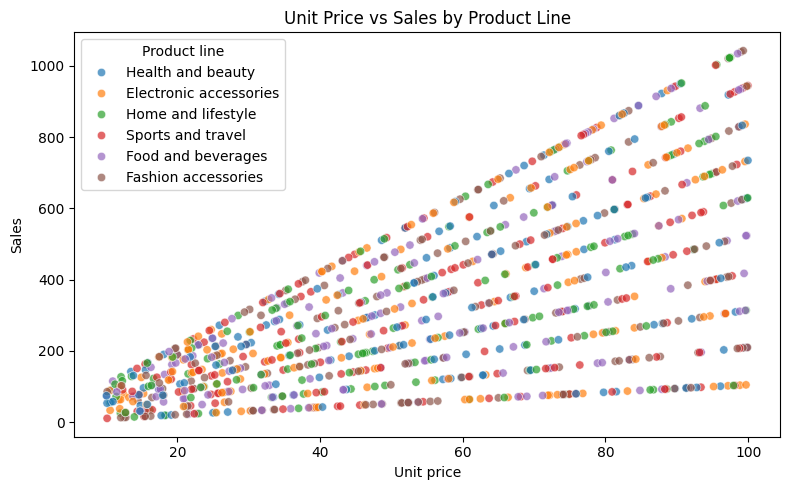

In [66]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Unit price", y="Sales", hue="Product line", alpha=0.7)
plt.title("Unit Price vs Sales by Product Line")
plt.tight_layout(); plt.show()

Customer Ratings by Product Line — Box Plot

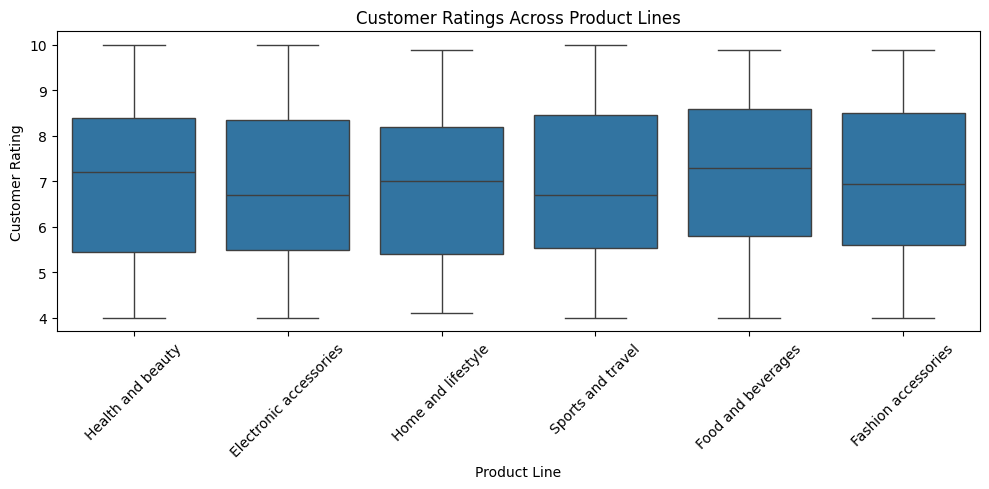

In [67]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Product line", y="Rating")

plt.title("Customer Ratings Across Product Lines")
plt.xlabel("Product Line")
plt.ylabel("Customer Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Conclusion

The **Consumer Product Preference Analysis** project provided practical experience in Exploratory Data Analysis (EDA) using Python. NumPy was used to perform numerical operations, while Pandas helped in data cleaning, manipulation, grouping, aggregation, and summarization. Matplotlib and Seaborn were used to create visualizations such as bar charts, line graphs, histograms, scatter plots, and heatmaps to understand sales patterns and customer purchasing behavior.

The analysis helped explore sales trends over time, compare sales across cities and product lines, examine the relationship between unit price and sales, and understand customer ratings. Sudden increases or peaks in the graphs highlighted periods or categories with higher sales, which could be investigated further using the dataset. Overall, this project demonstrated how Python libraries can transform raw supermarket sales data into meaningful insights and support data-driven decision-making.